# SANOS-KF fit vs. smoothness (snapshot)

Fits the `run_sanos_kf` model on one trade-date and overlays the fitted IV smile at a single
time window for **no smoothing** and several smoothness levels `eta`.

**Workflow:** run the notebook top-to-bottom **once** — the *Fit models* cell runs the heavy EKF
once per `eta` and caches everything. Then change `SNAPSHOT_FRAC` in the *Snapshot & plot* cell and
re-run **only that cell** to get a new plot at a different time. No re-fitting needed.

The curve for each `eta` is the model's *own* call price (rebuilt from the filter's posterior
state at the snapshot window, exactly as inside `run_sanos_kf`) evaluated on a fine strike grid
and inverted to IV. `eta=0` (no smoothing) gives the intrinsic discrete-call fit (kinks at the
density nodes); larger `eta` blurs each node by a lognormal of variance `eta * V_ATM`.

In [1]:
import sys
from pathlib import Path


def _find_root(start: Path) -> Path:
    for d in (start, *start.parents):
        if (d / "pyproject.toml").exists() and (d / "quantdata").is_dir():
            return d
    raise RuntimeError(f"quant_data project root not found above {start}")


PROJECT_ROOT = _find_root(Path.cwd().resolve())
for p in (
    PROJECT_ROOT,
    PROJECT_ROOT / "personal" / "shared_functions",
    PROJECT_ROOT / "personal" / "SANOS_KF",
    PROJECT_ROOT / "personal" / "Kalman_filter_spline",
):
    p = str(p)
    if p not in sys.path:
        sys.path.insert(0, p)

from datetime import date

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl

from personal.Kalman_filter_spline.surface_kalman_filters import build_iv_observations
from personal.SANOS_KF.sanos_kf import (
    SanosKFConfig,
    _estimate_atm_var,
    _invert_iv_vec,
    _make_exact_fns,
    build_exact_grid,
    run_sanos_kf,
)
from quantdata.massive.client import MassiveClient

/Users/elie/Documents/GitHub/quant_data/quantdata/__init__.py:212: UserWarning: Using cache mode 'on' as specified in environment variable QUANTDATA_CACHE_MODE.


In [2]:
# ── data knobs ──
TRADE_DATE = date(2024, 1, 3)
TICKER = "SPY"
MIN_TRADES = 0
PUTS_ONLY, CALLS_ONLY = True, False

# ── SANOS-KF hyperparameters (match three_model_comparison / sweep BASE best point) ──
SANOS_N_ANCHORS = 300
SANOS_K_MIN = -0.60
SANOS_K_MAX = 0.10
SANOS_BATCH_S = 1.0
SANOS_Q_SCALE_DLV = 1e-3
SANOS_P0_SCALE = 0.001
SANOS_ELL = 5.0
SANOS_SIGMA_INIT = 0.01
SANOS_CORRELATED = True

# ── smoothness levels to overlay (eta=None → no smoothing / intrinsic) ──
ETAS = [None, 0.06, 0.25, 0.5]

In [ ]:
client = MassiveClient()
df_tickers = pl.read_csv(PROJECT_ROOT / "personal" / f"spy_options_tickers_{TRADE_DATE}.csv")
df_spy = client.fetch_trades(TICKER, TRADE_DATE)

# IV-annotated quotes/trades (puts AND calls; the model subsets internally).
df_quotes, df_trades = build_iv_observations(df_tickers, TRADE_DATE, df_spy, min_trades=MIN_TRADES)
print(
    f"build_iv_observations: {df_quotes.height:,} quote rows, {df_quotes['strike'].n_unique()} strikes"
)

BS_NS = int(SANOS_BATCH_S * 1e9)
EVAL_IS_CALL = CALLS_ONLY if (CALLS_ONLY or PUTS_ONLY) else None

# Market quotes (pandas) on the fitted side, tagged by window — used for the snapshot scatter
# and for picking a window from SNAPSHOT_FRAC.
_qpd = df_quotes.to_pandas()
_qpd["window"] = _qpd["ts_ns"].astype("int64") // BS_NS
if EVAL_IS_CALL is not None:
    _qpd = _qpd[_qpd["is_call"] == EVAL_IS_CALL]
_wins = np.sort(_qpd["window"].unique())
print(f"{len(_wins)} populated windows on the fitted side")

Skipping O:SPY240105C00388000: no matched trades
Skipping O:SPY240105C00424000: no matched trades
Skipping O:SPY240105C00425000: no matched trades
Skipping O:SPY240105C00441000: no matched trades
Skipping O:SPY240105C00443000: no matched trades
Skipping O:SPY240105C00453000: no matched trades
Skipping O:SPY240105C00481000: 46 bad quotes


Skipping O:SPY240105C00482000: 64 bad quotes
Skipping O:SPY240105C00483000: 842 bad quotes
Skipping O:SPY240105C00484000: 2129 bad quotes
Skipping O:SPY240105C00485000: 3888 bad quotes
Skipping O:SPY240105C00486000: 4860 bad quotes
Skipping O:SPY240105C00487000: 1630 bad quotes
Skipping O:SPY240105C00488000: 136 bad quotes
Skipping O:SPY240105C00489000: 130 bad quotes
Skipping O:SPY240105C00490000: 218 bad quotes
Skipping O:SPY240105C00491000: 370 bad quotes
Skipping O:SPY240105C00492000: 341 bad quotes
Skipping O:SPY240105C00493000: 342 bad quotes
Skipping O:SPY240105C00494000: 290 bad quotes
Skipping O:SPY240105C00495000: 202 bad quotes
Skipping O:SPY240105C00498000: 178 bad quotes
Skipping O:SPY240105P00270000: 245 bad quotes
Skipping O:SPY240105P00368000: 429 bad quotes
Skipping O:SPY240105P00379000: 443 bad quotes
Skipping O:SPY240105P00380000: 584 bad quotes
Skipping O:SPY240105P00395000: 669 bad quotes
Skipping O:SPY240105P00398000: 682 bad quotes
Skipping O:SPY240105P00400000: 

Expiry 2024-01-05: implied forward from 28 strike(s)


build_iv_observations: 3,039,656 quote rows, 62 strikes
24119 populated windows on the fitted side


## Fit models (heavy — run once)

Runs the EKF once per `eta` and caches, per smoothness level: the model's observation closure
`obs_vec` plus the full posterior state history indexed by window. Re-run this only if you change
the data knobs, hyperparameters, or `ETAS`.

In [4]:
def make_cfg(eta):
    """Config for one smoothness level. eta=None → no smoothing (intrinsic)."""
    return SanosKFConfig(
        n_anchors=SANOS_N_ANCHORS,
        k_min=SANOS_K_MIN,
        k_max=SANOS_K_MAX,
        batch_seconds=SANOS_BATCH_S,
        smoothing=eta is not None,
        eta=0.0 if eta is None else float(eta),
        Q_scale_dlv=SANOS_Q_SCALE_DLV,
        P0_scale=SANOS_P0_SCALE,
        ell=SANOS_ELL,
        Sigma_init=SANOS_SIGMA_INIT,
        correlated=SANOS_CORRELATED,
        puts_only=PUTS_ONLY,
        calls_only=CALLS_ONLY,
    )


def fit_model(eta):
    """Run the EKF ONCE (heavy) and cache everything needed to evaluate the fitted smile at
    ANY snapshot window: the model's obs closure + the full posterior state history (indexed
    by window). Grid / payoff / smoothing kernel are rebuilt exactly as inside run_sanos_kf."""
    cfg = make_cfg(eta)
    _, _, df_state = run_sanos_kf(df_quotes, df_trades, cfg, return_state=True)

    grid_K, tte_ref = build_exact_grid(df_quotes, cfg)
    eff_eta = cfg.eta if cfg.smoothing else 0.0
    kernel_var = eff_eta * _estimate_atm_var(df_quotes, tte_ref) if eff_eta > 0.0 else 0.0
    xrow = np.concatenate(([2 * grid_K[0] - grid_K[1]], grid_K, [2 * grid_K[-1] - grid_K[-2]]))
    box = grid_K**2 / (xrow[2:] - xrow[:-2]) * tte_ref
    box[0] = 0.0
    box[-1] = 0.0
    pay_full = np.maximum(grid_K[np.newaxis, :] - grid_K[:, np.newaxis], 0.0)
    _, _, obs_vec, _, _ = _make_exact_fns(grid_K, box, pay_full, cfg.dlv_min, kernel_var=kernel_var)

    st = df_state.to_pandas()
    st["window"] = st["ts_ns"].astype("int64") // BS_NS
    st = st.sort_values("ts_ns").drop_duplicates("window", keep="last").set_index("window")
    xcols = [c for c in st.columns if c.startswith("x_")]
    return {"obs_vec": obs_vec, "state": st[xcols]}


def state_at(fit, window):
    """Posterior net-DLV² state at `window` (nearest populated window if exact is missing)."""
    s = fit["state"]
    if window in s.index:
        return s.loc[window].to_numpy(float)
    pos = s.index.get_indexer([window], method="nearest")[0]
    return s.iloc[pos].to_numpy(float)


FITS = {}
for _eta in ETAS:
    _label = "no smoothing" if _eta is None else f"eta={_eta:g}"
    FITS[_label] = fit_model(_eta)
    print(f"fitted {_label}")
print("\ndone — change SNAPSHOT_FRAC in the next cell and re-run it only (no refit needed)")

fitted no smoothing


fitted eta=0.06


fitted eta=0.25


fitted eta=0.5

done — change SNAPSHOT_FRAC in the next cell and re-run it only (no refit needed)


## Snapshot & plot (cheap — re-run after changing `SNAPSHOT_FRAC`)

snapshot window 1704300405  (2024-01-03 16:46:45 UTC)  fwd=469.80  T=0.0060


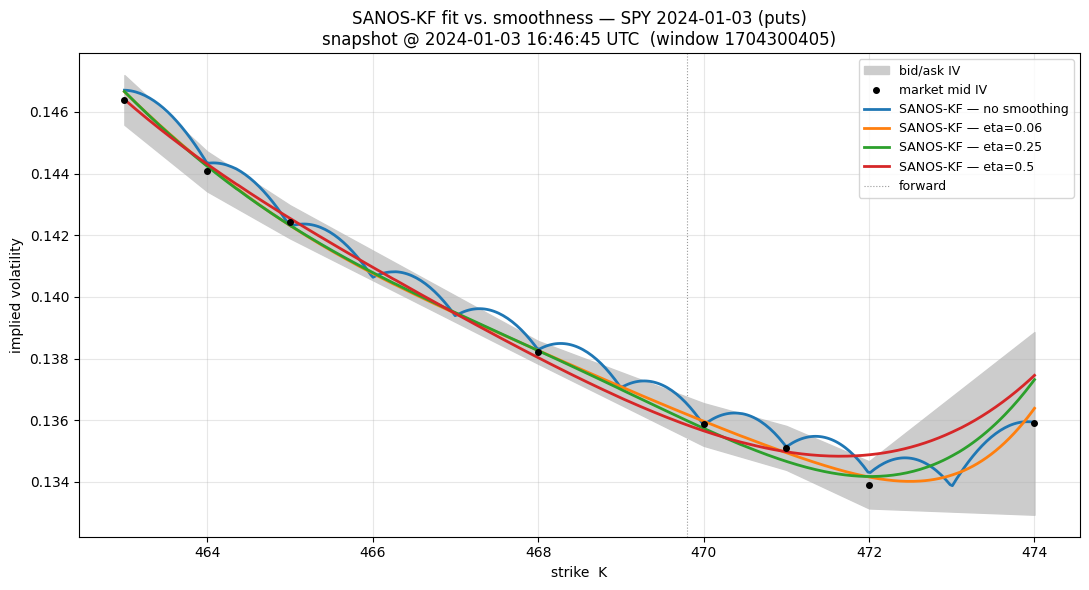

In [26]:
# ── change this and re-run THIS cell only (no refit) ──
SNAPSHOT_FRAC = 0.34  # fraction through the day's quote windows (0 = open, 1 = close)

SNAP_WINDOW = int(_wins[int(round(SNAPSHOT_FRAC * (len(_wins) - 1)))])
snap_clock = pd.to_datetime(SNAP_WINDOW * SANOS_BATCH_S, unit="s")

# Market smile at the snapshot window (one point per strike, last quote in the window).
mkt = (
    _qpd[_qpd["window"] == SNAP_WINDOW]
    .sort_values("ts_ns")
    .drop_duplicates("strike", keep="last")
    .sort_values("strike")
)
F_w = float(np.nanmedian(mkt["forward"].to_numpy(float)))
T_w = float(np.nanmedian(mkt["T"].to_numpy(float)))
K_mkt = mkt["strike"].to_numpy(float)

# Fine STRIKE grid spanning the snapshot's observed strikes (IV inversion still needs k=log(K/F)).
K_fine = np.linspace(float(K_mkt.min()), float(K_mkt.max()), 400)
k_fine = np.log(K_fine / F_w)

# Cheap: just re-evaluate each cached fit's obs closure at this window's state / forward.
curves = {}
for label, fit in FITS.items():
    x_snap = state_at(fit, SNAP_WINDOW)
    c_norm = np.asarray(fit["obs_vec"](x_snap, K_fine, F_w)) / F_w  # F-normalized call C/(F·df)
    curves[label] = _invert_iv_vec(c_norm, k_fine, np.full_like(K_fine, T_w))

print(f"snapshot window {SNAP_WINDOW}  ({snap_clock} UTC)  fwd={F_w:.2f}  T={T_w:.4f}")

fig, ax = plt.subplots(figsize=(11, 6))
ax.fill_between(
    K_mkt,
    mkt["bid_iv"].to_numpy(float),
    mkt["ask_iv"].to_numpy(float),
    color="0.8",
    label="bid/ask IV",
    zorder=1,
)
ax.scatter(
    K_mkt, mkt["observed_iv"].to_numpy(float), s=16, color="black", label="market mid IV", zorder=5
)
for label, iv_fine in curves.items():
    ax.plot(K_fine, iv_fine, lw=2, label=f"SANOS-KF — {label}", zorder=4)

side = "puts" if PUTS_ONLY else ("calls" if CALLS_ONLY else "calls+puts")
ax.axvline(F_w, color="0.6", lw=0.8, ls=":", zorder=0, label="forward")
ax.set_xlabel("strike  K")
ax.set_ylabel("implied volatility")
ax.set_title(
    f"SANOS-KF fit vs. smoothness — {TICKER} {TRADE_DATE} ({side})\n"
    f"snapshot @ {snap_clock} UTC  (window {SNAP_WINDOW})"
)
ax.legend(loc="upper right", fontsize=9)
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()